# **Customer Churn Prediction**

## **Import Required Libraries**

In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

## **Read the Dataset**

In [6]:
df = pd.read_excel("Customer_Churn_Prediction_Codec.xlsx")

df.head()

,CustomerID,Gender,Age,SeniorCitizen,MaritalStatus,Dependents,Education,EmploymentStatus,Income,TenureMonths,...,PaymentMethod,MonthlyCharges,TotalCharges,AvgMonthlyUsageGB,NumSupportTickets,LatePayments,SatisfactionScore,CityTier,Referral,Churn
0,CUST0000001,Female,25,No,Married,No,High School,Employed,179009,41,...,Mailed check,80.30,3272.42,588.1,1,1,5,Tier-2,No,No
1,CUST0000002,Male,65,Yes,Married,Yes,Post Graduate,Student,113300,66,...,Bank transfer,96.53,6398.54,342.8,1,4,3,Tier-2,Yes,No
2,CUST0000003,Female,54,No,Married,Yes,Graduate,Self-Employed,49985,29,...,Credit card,111.90,3228.65,168.7,8,5,1,Tier-1,Yes,Yes
3,CUST0000004,Female,59,No,Married,Yes,Graduate,Student,137971,59,...,Mailed check,116.43,6858.98,124.8,5,1,4,Tier-2,Yes,No
4,CUST0000005,Male,46,No,Single,Yes,Post Graduate,Employed,161248,2,...,Mailed check,31.06,69.15,575.4,8,6,4,Tier-3,No,Yes


## **Dataset Information**

In [8]:
df.shape

(20000, 31)

In [9]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'SeniorCitizen', 'MaritalStatus',
       'Dependents', 'Education', 'EmploymentStatus', 'Income', 'TenureMonths',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'AvgMonthlyUsageGB',
       'NumSupportTickets', 'LatePayments', 'SatisfactionScore', 'CityTier',
       'Referral', 'Churn'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         20000 non-null  object 
 1   Gender             20000 non-null  object 
 2   Age                20000 non-null  int64  
 3   SeniorCitizen      20000 non-null  object 
 4   MaritalStatus      20000 non-null  object 
 5   Dependents         20000 non-null  object 
 6   Education          20000 non-null  object 
 7   EmploymentStatus   20000 non-null  object 
 8   Income             20000 non-null  int64  
 9   TenureMonths       20000 non-null  int64  
 10  PhoneService       20000 non-null  object 
 11  MultipleLines      20000 non-null  object 
 12  InternetService    20000 non-null  object 
 13  OnlineSecurity     20000 non-null  object 
 14  OnlineBackup       20000 non-null  object 
 15  DeviceProtection   20000 non-null  object 
 16  TechSupport        200

In [11]:
df.describe()

,Age,Income,TenureMonths,MonthlyCharges,TotalCharges,AvgMonthlyUsageGB,NumSupportTickets,LatePayments,SatisfactionScore
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,46.552550,98652.507800,36.354050,79.913252,2909.377386,302.687035,3.994350,2.989050,2.999550
std,16.772394,46833.313482,20.832371,34.635237,2211.465410,170.843739,2.576635,2.014506,1.415927
min,18.000000,18002.000000,1.000000,20.000000,-11.100000,10.100000,0.000000,0.000000,1.000000
25%,32.000000,57845.500000,18.000000,49.980000,1128.975000,153.400000,2.000000,1.000000,2.000000
50%,47.000000,98005.500000,36.000000,79.865000,2352.305000,300.500000,4.000000,3.000000,3.000000
75%,61.000000,139579.500000,54.000000,110.165000,4292.185000,450.900000,6.000000,5.000000,4.000000
max,75.000000,179978.000000,72.000000,140.000000,10059.350000,599.900000,8.000000,6.000000,5.000000


In [12]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
SeniorCitizen,0
MaritalStatus,0
Dependents,0
Education,0
EmploymentStatus,0
Income,0
TenureMonths,0


## **Exploratory Data Analysis (EDA)**

### **Churn Distribution**

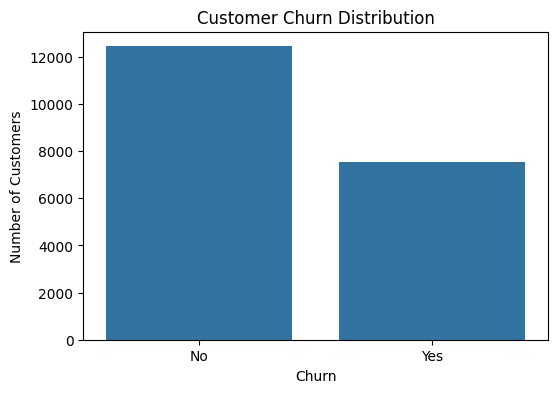

In [13]:
plt.figure(figsize=(6,4))

sns.countplot(x='Churn', data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

### **Gender vs Churn**

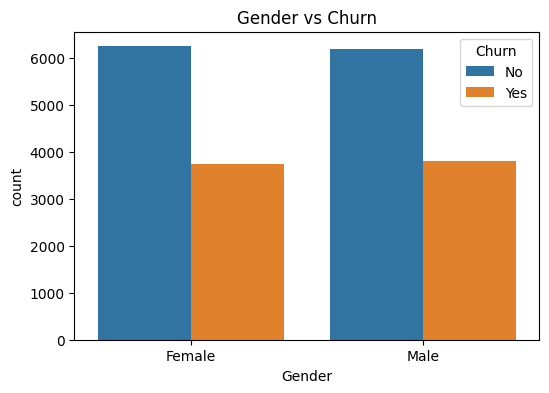

In [14]:
plt.figure(figsize=(6,4))

sns.countplot(x='Gender', hue='Churn', data=df)

plt.title("Gender vs Churn")

plt.show()

### **Internet Service vs Churn**

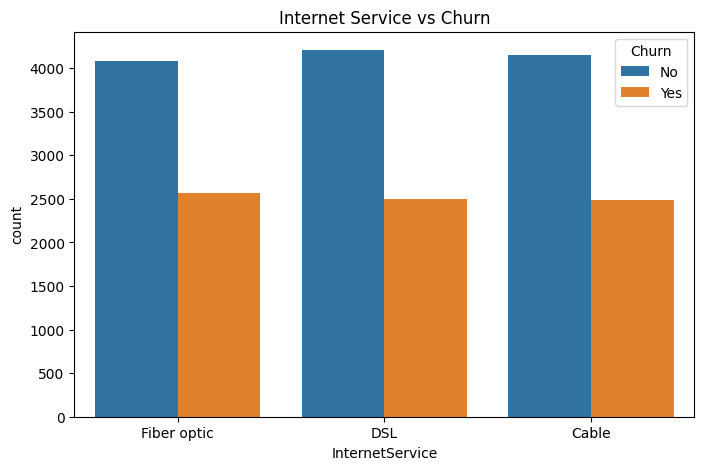

In [15]:
plt.figure(figsize=(8,5))

sns.countplot(x='InternetService', hue='Churn', data=df)

plt.title("Internet Service vs Churn")

plt.show()

### **Payment Method vs Churn**

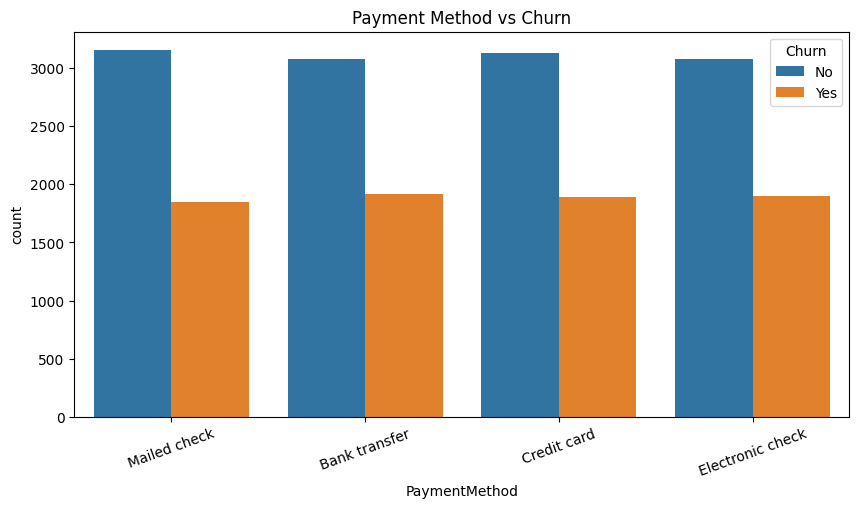

In [16]:
plt.figure(figsize=(10,5))

sns.countplot(x='PaymentMethod', hue='Churn', data=df)

plt.title("Payment Method vs Churn")

plt.xticks(rotation=20)

plt.show()

### **Distribution of Monthly Charges**

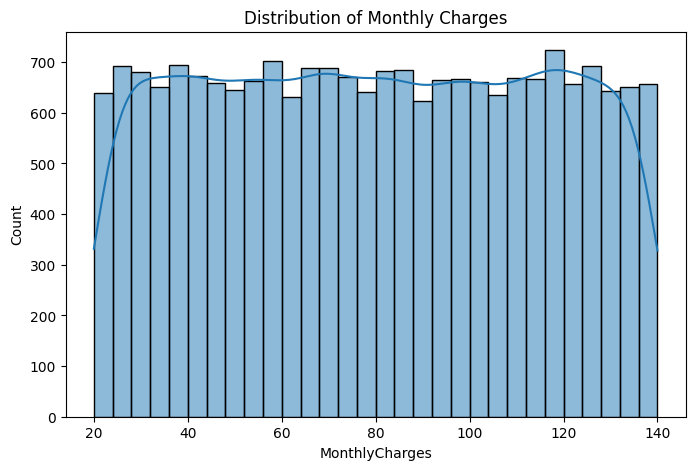

In [18]:
plt.figure(figsize=(8,5))

sns.histplot(df['MonthlyCharges'], bins=30, kde=True)

plt.title("Distribution of Monthly Charges")

plt.show()

### **Correlation Heatmap**

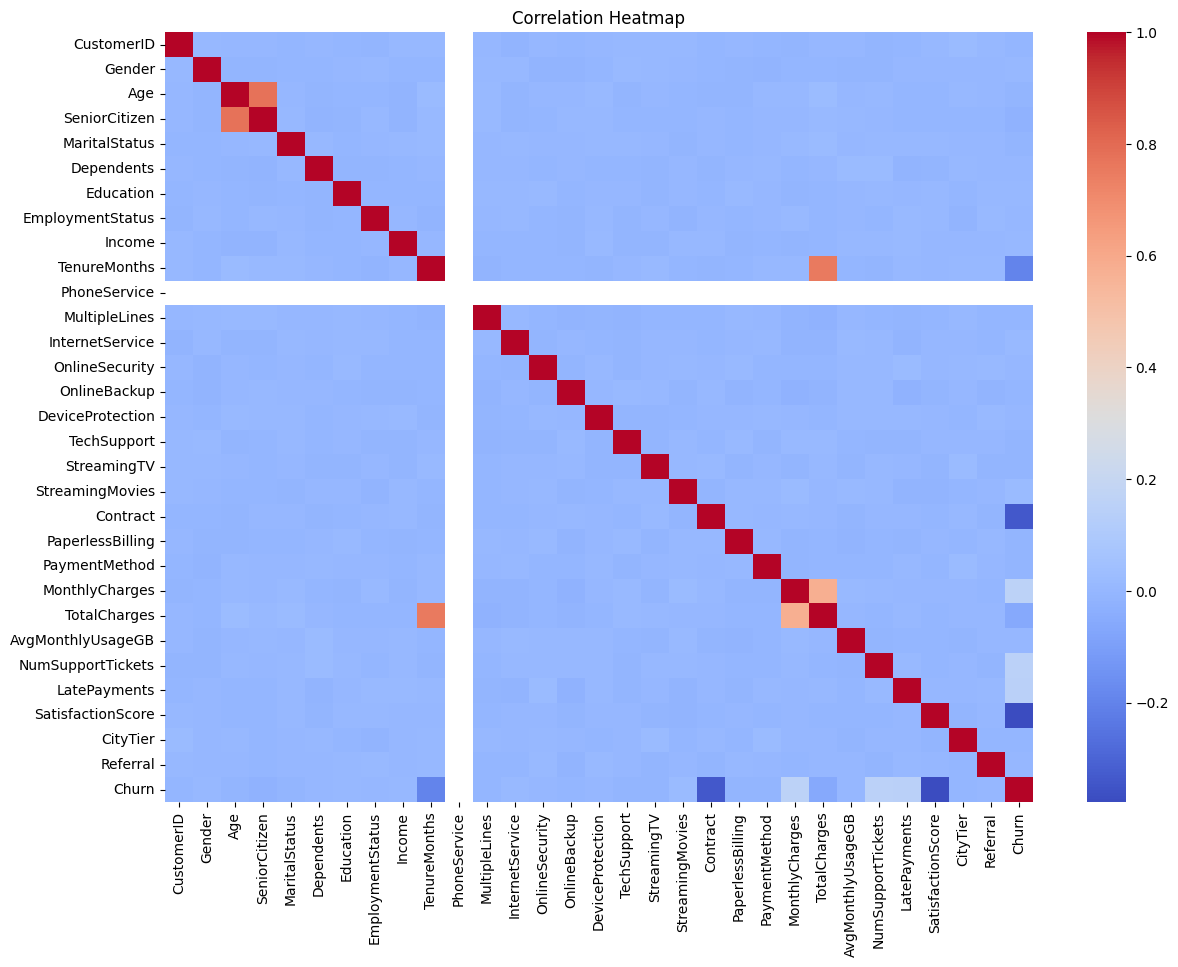

In [17]:
label_encoder = LabelEncoder()

df_encoded = df.copy()

for column in df_encoded.columns:
    if df_encoded[column].dtype == 'object':
        df_encoded[column] = label_encoder.fit_transform(df_encoded[column])

plt.figure(figsize=(14,10))

sns.heatmap(df_encoded.corr(), cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

## **Data Preprocessing**

### **Step 1: Encode Categorical Variables**

In [19]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df_encoded = df.copy()

for column in df_encoded.columns:
    if df_encoded[column].dtype == 'object':
        df_encoded[column] = label_encoder.fit_transform(df_encoded[column])

df_encoded.head()

,CustomerID,Gender,Age,SeniorCitizen,MaritalStatus,Dependents,Education,EmploymentStatus,Income,TenureMonths,...,PaymentMethod,MonthlyCharges,TotalCharges,AvgMonthlyUsageGB,NumSupportTickets,LatePayments,SatisfactionScore,CityTier,Referral,Churn
0,0,0,25,0,0,0,1,0,179009,41,...,3,80.30,3272.42,588.1,1,1,5,1,0,0
1,1,1,65,1,0,1,2,3,113300,66,...,0,96.53,6398.54,342.8,1,4,3,1,1,0
2,2,0,54,0,0,1,0,2,49985,29,...,1,111.90,3228.65,168.7,8,5,1,0,1,1
3,3,0,59,0,0,1,0,3,137971,59,...,3,116.43,6858.98,124.8,5,1,4,1,1,0
4,4,1,46,0,1,1,2,0,161248,2,...,3,31.06,69.15,575.4,8,6,4,2,0,1


### **Step 2: Define Features and Target**

In [20]:
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]

### **Step 3: Train-Test Split**

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data :", X_train.shape)
print("Testing Data  :", X_test.shape)

Training Data : (16000, 30)
Testing Data  : (4000, 30)


## **Logistic Regression Model**

In [22]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

### **Evaluation**

In [23]:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

print("Logistic Regression")

print("Accuracy :", round(accuracy_score(y_test, lr_pred), 4))
print("Recall   :", round(recall_score(y_test, lr_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, lr_prob), 4))

Logistic Regression
Accuracy : 0.7805
Recall   : 0.6499
ROC-AUC  : 0.8407


## **Random Forest Model**

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

### **Evaluation**

In [25]:
print("Random Forest")

print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Recall   :", round(recall_score(y_test, rf_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 4))

Random Forest
Accuracy : 0.951
Recall   : 0.8783
ROC-AUC  : 0.9405


## **XGBoost Model**

In [26]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

### **Evaluation**

In [27]:
print("XGBoost")

print("Accuracy :", round(accuracy_score(y_test, xgb_pred), 4))
print("Recall   :", round(recall_score(y_test, xgb_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, xgb_prob), 4))

XGBoost
Accuracy : 0.9527
Recall   : 0.8789
ROC-AUC  : 0.9396


## **Model Comparison**

In [28]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, xgb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, xgb_prob)
    ]
})

results

,Model,Accuracy,Recall,ROC-AUC
0,Logistic Regression,0.78050,0.649869,0.840750
1,Random Forest,0.95100,0.878272,0.940536
2,XGBoost,0.95275,0.878927,0.939590


## **Conclusion**

- This project analyzed customer churn data using Exploratory Data Analysis (EDA) and three classification models: Logistic Regression, Random Forest, and XGBoost.

- The models were evaluated using Accuracy, Recall, and ROC-AUC. Comparing these metrics helped identify the model that performed best for predicting customer churn.

- This analysis can help organizations identify customers at risk of leaving and support strategies to improve customer retention.